# 07E - Going further: vibrations

**MATH 331 - Differential Equations.** Lecture plan: after Session 14 (how the roots move with the damping; energy; areas in the plane of states).

**This notebook is optional.** It goes beyond what the course asks. Read notebook 07 first.

**References**
* [L] J. Lebl, *Notes on Diffy Qs*: Section 2.4, Mechanical vibrations (notation $\omega_0$, $p$;
  Example 2.4.1); Section 2.4 also writes the circuit equation for the **current**.
* [AD] W.A. Adkins and M.G. Davidson, *Ordinary Differential Equations* (Springer, 2012): Section
  3.6, Spring Systems (Example 3); Section 3.7, RCL Circuits; Section 3.3 (Abel's formula).
* Notebooks 05 and 05E (the Wronskian as an area), 06 (the characteristic equation), 07.
* The conservation of area for $c = 0$ is the simplest case of Liouville's theorem of classical
  mechanics; the logarithmic decrement is a classical laboratory method.

**What you will see**
1. How the two roots move in the complex plane as the damping grows, and why the **critical**
   damping gives the fastest return to rest.
2. Where the energy goes.
3. A whole cloud of initial states followed in time: its area obeys Abel's theorem.
4. The circuit again: charge, current and heat.
5. A map of all the equations $y'' + b\,y' + c\,y = 0$ at once.

In [1]:
# --- Setup ---------------------------------------------------------------------
# odelib.py lives next to the notebooks: it contains the tested helper functions
# (here: free_response, damping_regime, characteristic_roots, constant_coefficient_solution).
import sys
import pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import cumulative_trapezoid
from IPython.display import Math, display                 # noqa: F401  (not used in every notebook)
from ipywidgets import FloatSlider, IntSlider, interact    # noqa: F401

import odelib as ol

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 11, "legend.fontsize": 9})
print("numpy", np.__version__, "| sympy", sp.__version__)

numpy 2.5.4 | sympy 1.14.0


## 1. How the roots move as the damping grows

Notation of notebook 07: $m\,x'' + c\,x' + k\,x = 0$, $\omega_0 = \sqrt{k/m}$, $p = c/(2m)$,
$c_{crit} = 2\sqrt{mk}$. One more number, the **damping ratio**

$$ \zeta = \frac{c}{c_{crit}} = \frac{p}{\omega_0} $$

(no units: $\zeta < 1$ underdamped, $\zeta = 1$ critical, $\zeta > 1$ overdamped).

Keep $m$ and $k$ fixed and let $c$ grow from 0. The roots are $r = -p \pm \sqrt{p^2 - \omega_0^2}$
and their product is always $r_1r_2 = k/m = \omega_0^2$.

* $c = 0$: the roots are $\pm i\,\omega_0$, on the imaginary axis.
* $0 < c < c_{crit}$: $r = -p \pm i\,\omega_1$ and $|r|^2 = p^2 + \omega_1^2 = \omega_0^2$: the two
  roots move on the **circle of radius $\omega_0$**, towards the left.
* $c = c_{crit}$: they meet on the real axis at $-\omega_0$.
* $c > c_{crit}$: they separate along the real axis. Their product stays $\omega_0^2$, so while
  one runs away to the left, the other **comes back towards 0**.

For large $t$ a solution behaves like $e^{rt}$ with the root nearest to the imaginary axis (for
almost all initial data; at $\zeta = 1$ like $t\,e^{-\omega_0t}$). Call
$\sigma = -\max \mathrm{Re}\, r$ the **decay rate**:

$$ \sigma = \begin{cases} \zeta\,\omega_0, & \zeta \le 1,\\[2pt] \omega_0\big(\zeta - \sqrt{\zeta^2 - 1}\big), & \zeta \ge 1 . \end{cases} $$

It is largest at $\zeta = 1$. That is the precise meaning of "more damping is not better" in
notebook 07: door closers and measuring instruments are built with $\zeta$ close to 1.

Before running the cell: where are the roots for $\zeta = 0.5$, and what is the decay rate, if
$\omega_0 = 2$?

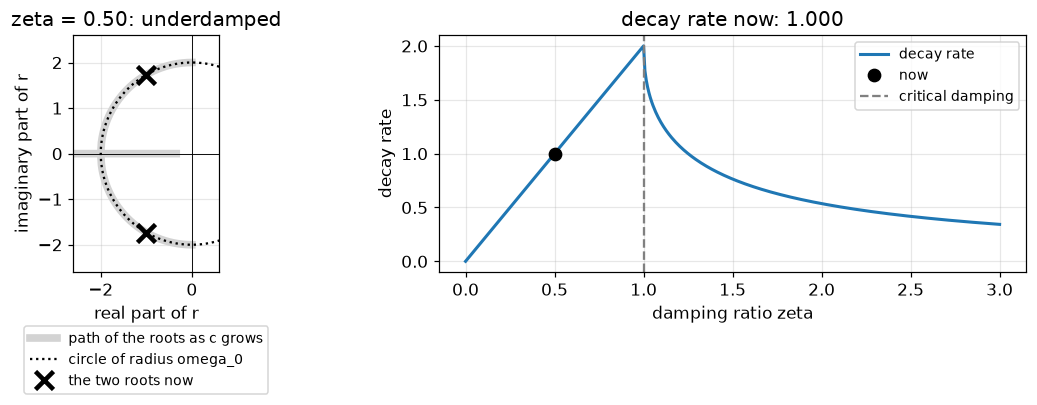

In [2]:
FIGURE_SIZE = (11.0, 4.0)
N_POINTS = 400
LOCUS_FACTOR = 3.0                          # the pictures show c from 0 to 3 times the critical value
MARGIN = 1.3
PATH_WIDTH = 5
LEGEND_BELOW = (0.5, -0.2)                 # position of a legend placed under the axes
BALANCE_TOLERANCE = 1e-4                # allowed error in the energy balance
DEFAULTS = {"c": 2.0, "m": 1.0, "k": 4.0}


def decay_rate(m, c, k):
    # minus the largest real part of the two roots
    return -max(root.real for root in ol.characteristic_roots(m, c, k))


def plot_root_locus(c=DEFAULTS["c"], m=DEFAULTS["m"], k=DEFAULTS["k"]):
    # left: the path of the roots as c grows, and the roots now; right: decay rate against the damping ratio
    omega_0, critical = np.sqrt(k / m), 2 * np.sqrt(m * k)
    dampings = np.linspace(0.0, LOCUS_FACTOR * critical, N_POINTS)
    paths = np.array([ol.characteristic_roots(m, value, k) for value in dampings])
    now = ol.characteristic_roots(m, c, k)

    fig, (left, right) = plt.subplots(1, 2, figsize=FIGURE_SIZE)
    left.plot(paths[:, 0].real, paths[:, 0].imag, "-", color="lightgray", linewidth=PATH_WIDTH,
              label="path of the roots as c grows")
    left.plot(paths[:, 1].real, paths[:, 1].imag, "-", color="lightgray", linewidth=PATH_WIDTH)
    angles = np.linspace(0.0, 2 * np.pi, N_POINTS)
    left.plot(omega_0 * np.cos(angles), omega_0 * np.sin(angles), ":", color="black", label="circle of radius omega_0")
    left.plot([root.real for root in now], [root.imag for root in now], "x", color="black", markersize=12,
              markeredgewidth=3, label="the two roots now")
    left.axhline(0.0, color="black", linewidth=0.6)
    left.axvline(0.0, color="black", linewidth=0.6)
    reach = MARGIN * max(omega_0, max(abs(root.real) for root in now))
    left.set_xlim(-reach, MARGIN * omega_0 - omega_0)
    left.set_ylim(-MARGIN * omega_0, MARGIN * omega_0)
    left.set_aspect("equal")                              # so that the circle looks like a circle
    left.set_xlabel("real part of r")
    left.set_ylabel("imaginary part of r")
    left.set_title(f"zeta = {c / critical:.2f}: {ol.damping_regime(m, c, k)}")
    left.legend(loc="upper center", bbox_to_anchor=LEGEND_BELOW)       # below the picture: it must not hide a root

    right.plot(dampings / critical, [decay_rate(m, value, k) for value in dampings], "-", linewidth=2, label="decay rate")
    right.plot(c / critical, decay_rate(m, c, k), "o", color="black", markersize=8, label="now")
    right.axvline(1.0, linestyle="--", color="gray", label="critical damping")
    right.set_xlabel("damping ratio zeta")
    right.set_ylabel("decay rate")
    right.set_title(f"decay rate now: {decay_rate(m, c, k):.3f}")
    right.legend(loc="upper right")
    plt.tight_layout()
    plt.show()


plot_root_locus()

ratios = np.linspace(0.0, LOCUS_FACTOR, N_POINTS)
formula = np.where(ratios <= 1, ratios, ratios - np.sqrt(np.maximum(ratios ** 2 - 1, 0.0))) * np.sqrt(DEFAULTS["k"] / DEFAULTS["m"])
computed = [decay_rate(DEFAULTS["m"], ratio * 2 * np.sqrt(DEFAULTS["m"] * DEFAULTS["k"]), DEFAULTS["k"]) for ratio in ratios]
assert np.allclose(formula, computed)                      # the formula for the decay rate

In [3]:
C_RANGE = (0.0, 12.0, 0.1)                  # minimum, maximum, step
M_RANGE = (0.25, 4.0, 0.25)
K_RANGE = (0.5, 16.0, 0.5)

interact(plot_root_locus,
         c=FloatSlider(value=DEFAULTS["c"], min=C_RANGE[0], max=C_RANGE[1], step=C_RANGE[2], description="c",
                       continuous_update=False),
         m=FloatSlider(value=DEFAULTS["m"], min=M_RANGE[0], max=M_RANGE[1], step=M_RANGE[2], description="m",
                       continuous_update=False),
         k=FloatSlider(value=DEFAULTS["k"], min=K_RANGE[0], max=K_RANGE[1], step=K_RANGE[2], description="k",
                       continuous_update=False));

interactive(children=(FloatSlider(value=2.0, continuous_update=False, description='c', max=12.0), FloatSlider(...

*The static plot shows*, for $m = 1$, $k = 4$, $c = 2$ ($\zeta = 0.5$). Left: the complex plane.
The two crosses, the roots $-1 \pm i\sqrt3$, lie on the dotted circle of radius 2; the wide gray
path follows the circle from $\pm 2i$ to the point $-2$ and then continues along the real axis in both
directions. Right: the decay rate against $\zeta$: a straight line rising to 2 at $\zeta = 1$
(dashed vertical line), then a curve falling back, to about 0.34 at $\zeta = 3$. The black dot is
at $\zeta = 0.5$, decay rate 1.

(Answer: on the circle, at $-1 \pm 1.732\,i$; the decay rate is $\zeta\,\omega_0 = 1$.)

With the slider, move $c$ slowly through 4: the crosses meet and then separate, and the dot on
the right passes over the top.

## 2. Where does the energy go?

The mechanical energy is kinetic plus elastic:

$$ E(t) = \tfrac12\,m\,x'^2 + \tfrac12\,k\,x^2 . $$

Differentiate, and use the equation in the form $m\,x'' + k\,x = -c\,x'$:

$$ \frac{dE}{dt} = m\,x'x'' + k\,x\,x' = x'\,(m\,x'' + k\,x) = -c\,x'^2 \le 0 . $$

* $c = 0$: the energy is **constant**. In the plane of states $(x, x')$ the motion stays on the
  ellipse $\tfrac12mx'^2 + \tfrac12kx^2 = E$.
* $c > 0$: the damper turns mechanical energy into heat at the rate $c\,x'^2$. The loss stops for
  an instant whenever $x' = 0$ (the body is turning back): the energy goes down like a
  **staircase**.

A useful remark for the code: differentiate the equation and you see that the velocity $x'$ is
itself a solution, with initial values $x'(0) = v_0$ and $x''(0) = -(c\,v_0 + k\,x_0)/m$. So the
library gives the velocity exactly, with no numerical derivative.

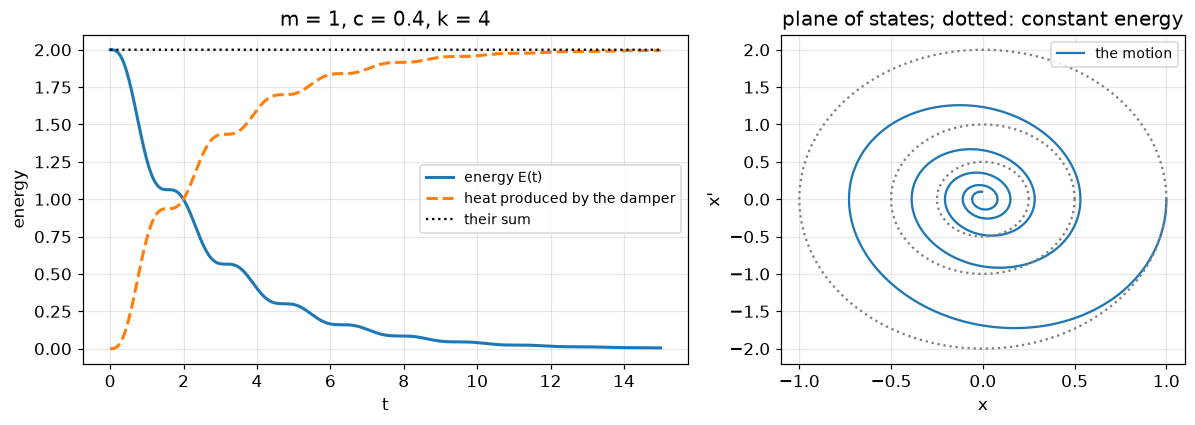

initial energy 2; energy left at t = 15: 0.0051; largest error in the balance: 5.3e-06


In [4]:
MASS, DAMPING, STIFFNESS = 1.0, 0.4, 4.0
X_START, V_START = 1.0, 0.0
ENERGY_TIME = 15.0
N_FINE = 3001
SHARES = (1.0, 0.25, 0.0625)                # ellipses drawn at these fractions of the initial energy


def velocity(t, m, c, k, x0, v0):
    # the velocity is a solution of the same equation
    return ol.free_response(t, m, c, k, v0, -(c * v0 + k * x0) / m)


times = np.linspace(0.0, ENERGY_TIME, N_FINE)
position = ol.free_response(times, MASS, DAMPING, STIFFNESS, X_START, V_START)
speed = velocity(times, MASS, DAMPING, STIFFNESS, X_START, V_START)
energy = 0.5 * MASS * speed ** 2 + 0.5 * STIFFNESS * position ** 2
heat = cumulative_trapezoid(DAMPING * speed ** 2, times, initial=0.0)       # integral of c x'^2 from 0 to t

fig, (left, right) = plt.subplots(1, 2, figsize=FIGURE_SIZE, gridspec_kw={"width_ratios": [1.5, 1]})
left.plot(times, energy, "-", linewidth=2, label="energy E(t)")
left.plot(times, heat, "--", linewidth=2, label="heat produced by the damper")
left.plot(times, energy + heat, ":", color="black", label="their sum")
left.set_xlabel("t")
left.set_ylabel("energy")
left.set_title(f"m = {MASS:g}, c = {DAMPING:g}, k = {STIFFNESS:g}")
left.legend(loc="center right")

right.plot(position, speed, "-", linewidth=1.5, label="the motion")
angles = np.linspace(0.0, 2 * np.pi, N_POINTS)
for share in SHARES:
    level = share * energy[0]
    right.plot(np.sqrt(2 * level / STIFFNESS) * np.cos(angles), np.sqrt(2 * level / MASS) * np.sin(angles), ":", color="gray")
right.set_xlabel("x")
right.set_ylabel("x'")
right.set_title("plane of states; dotted: constant energy")
right.legend(loc="upper right")
plt.tight_layout()
plt.show()

balance = np.max(np.abs(energy + heat - energy[0]))
print(f"initial energy {energy[0]:g}; energy left at t = {ENERGY_TIME:g}: {energy[-1]:.4f}; "
      f"largest error in the balance: {balance:.1e}")
assert balance < BALANCE_TOLERANCE

*The plot shows*, for $m = 1$, $c = 0.4$, $k = 4$, released from rest at $x = 1$. Left: the energy
(solid) falls from 2 towards 0 in steps, flat for an instant about every 1.6 time units; the heat
(dashed) rises by the same steps; their sum (dotted) is the horizontal line at 2. Right: in the
plane of states the motion is a spiral that winds clockwise into the origin, crossing the dotted
ellipses of constant energy inwards.

For the circuit the same computation gives: $\tfrac12L\,I^2 + \dfrac{Q^2}{2C}$ (energy of the
coil plus energy of the capacitor) decreases at the rate $R\,I^2$, the heat in the resistor.

## 3. A cloud of initial states

Notebook 05E, Section 1: the Wronskian of two solutions is the **area** of the parallelogram
spanned by their states $(x, x')$, and Abel's theorem says how it changes. For
$x'' + \dfrac cm\,x' + \dfrac km\,x = 0$:

$$ W(t) = W(0)\,e^{-(c/m)\,t} . $$

Because the equation is linear, the motion sends a square of initial states to a parallelogram,
and **any** region to a region whose area is multiplied by the same factor. Careful with the
letter: the $p(x)$ of Abel's theorem is the whole coefficient of $x'$, here $c/m$, which is $2p$
in the notation of notebook 07. Below, a square
cloud of 400 initial states is followed in time.

Predict before moving the sliders:

1. With $c = 0$, what happens to the area of the cloud? And to its shape?
2. With $c > 0$ fixed, the spring is made stiffer. Does the area shrink faster?

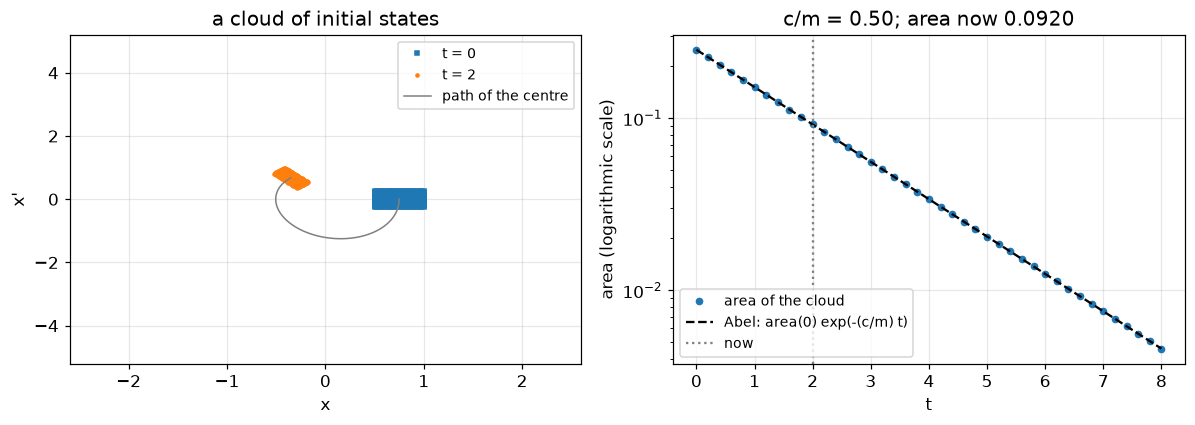

In [5]:
CLOUD_DEFAULTS = {"c": 0.5, "m": 1.0, "k": 4.0, "t_now": 2.0}
SQUARE_X, SQUARE_V = (0.5, 1.0), (-0.25, 0.25)          # the square of initial states
SIDE_POINTS = 20
CLOUD_TIME = 8.0
N_AREAS = 41


def flow(t, m, c, k):
    # the matrix that sends the state (x, x') at time 0 to the state at time t
    return np.array([[ol.free_response(t, m, c, k, 1.0, 0.0), ol.free_response(t, m, c, k, 0.0, 1.0)],
                     [velocity(t, m, c, k, 1.0, 0.0), velocity(t, m, c, k, 0.0, 1.0)]])


def shoelace(points):
    # area of a polygon from the coordinates of its corners (one corner per column)
    x, v = points
    return 0.5 * abs(np.dot(x, np.roll(v, -1)) - np.dot(v, np.roll(x, -1)))


def plot_cloud(c=CLOUD_DEFAULTS["c"], m=CLOUD_DEFAULTS["m"], k=CLOUD_DEFAULTS["k"], t_now=CLOUD_DEFAULTS["t_now"]):
    # left: the cloud at time 0 and at time t_now; right: its area against time, and Abel's formula
    grid_x, grid_v = np.meshgrid(np.linspace(*SQUARE_X, SIDE_POINTS), np.linspace(*SQUARE_V, SIDE_POINTS))
    cloud = np.vstack([grid_x.ravel(), grid_v.ravel()])
    corners = np.array([[SQUARE_X[0], SQUARE_X[1], SQUARE_X[1], SQUARE_X[0]],
                        [SQUARE_V[0], SQUARE_V[0], SQUARE_V[1], SQUARE_V[1]]])
    centre = np.array([np.mean(SQUARE_X), np.mean(SQUARE_V)])
    moved = flow(t_now, m, c, k) @ cloud

    fig, (left, right) = plt.subplots(1, 2, figsize=FIGURE_SIZE)
    left.plot(cloud[0], cloud[1], "s", markersize=2, label="t = 0")
    left.plot(moved[0], moved[1], "o", markersize=2, label=f"t = {t_now:g}")
    path_times = np.linspace(0.0, t_now, N_POINTS)
    left.plot(ol.free_response(path_times, m, c, k, *centre), velocity(path_times, m, c, k, *centre), "-", color="gray",
              linewidth=1, label="path of the centre")
    reach = MARGIN * max(1.0, np.sqrt(k / m))
    left.set_xlim(-reach, reach)
    left.set_ylim(-2 * reach, 2 * reach)
    left.set_xlabel("x")
    left.set_ylabel("x'")
    left.set_title("a cloud of initial states")
    left.legend(loc="upper right")

    area_times = np.linspace(0.0, CLOUD_TIME, N_AREAS)
    areas = np.array([shoelace(flow(value, m, c, k) @ corners) for value in area_times])
    abel = shoelace(corners) * np.exp(-(c / m) * area_times)
    right.semilogy(area_times, areas, "o", markersize=4, label="area of the cloud")
    right.semilogy(area_times, abel, "--", color="black", label="Abel: area(0) exp(-(c/m) t)")
    right.axvline(t_now, linestyle=":", color="gray", label="now")
    right.set_xlabel("t")
    right.set_ylabel("area (logarithmic scale)")
    right.set_title(f"c/m = {c / m:.2f}; area now {shoelace(flow(t_now, m, c, k) @ corners):.4f}")
    right.legend(loc="lower left")
    plt.tight_layout()
    plt.show()
    assert np.allclose(areas, abel)                        # Abel's theorem, for every choice of the sliders


plot_cloud()

In [6]:
CLOUD_C = (0.0, 2.0, 0.1)                   # minimum, maximum, step
CLOUD_M = (0.5, 3.0, 0.25)
CLOUD_K = (1.0, 10.0, 0.5)
CLOUD_T = (0.0, CLOUD_TIME, 0.25)

interact(plot_cloud,
         c=FloatSlider(value=CLOUD_DEFAULTS["c"], min=CLOUD_C[0], max=CLOUD_C[1], step=CLOUD_C[2], description="c",
                       continuous_update=False),
         m=FloatSlider(value=CLOUD_DEFAULTS["m"], min=CLOUD_M[0], max=CLOUD_M[1], step=CLOUD_M[2], description="m",
                       continuous_update=False),
         k=FloatSlider(value=CLOUD_DEFAULTS["k"], min=CLOUD_K[0], max=CLOUD_K[1], step=CLOUD_K[2], description="k",
                       continuous_update=False),
         t_now=FloatSlider(value=CLOUD_DEFAULTS["t_now"], min=CLOUD_T[0], max=CLOUD_T[1], step=CLOUD_T[2], description="t",
                           continuous_update=False));

interactive(children=(FloatSlider(value=0.5, continuous_update=False, description='c', max=2.0), FloatSlider(v...

*The static plot shows*, for $m = 1$, $c = 0.5$, $k = 4$. Left: the plane of states. The square
of small squares at $t = 0$ (between $x = 0.5$ and $1$) has become, at $t = 2$, a smaller slanted
parallelogram of dots on the other side of the vertical axis, near $(-0.35, 0.7)$; the gray curve is the path of its centre.
Right: the area of the cloud on a logarithmic scale: the dots lie on the dashed straight line of
Abel's formula, from 0.25 at $t = 0$ down to about 0.005 at $t = 8$; at $t = 2$ the area is 0.092.

(1: the area stays exactly 0.25: this is the simplest case of Liouville's theorem. The shape
does change: the square turns and is sheared. 2: no: the area law contains $c/m$ only; $k$
changes the motion, not the area.)

## 4. The circuit again: charge, current and heat

Notebook 07, Section 5: for a coil, a resistor and a capacitor in series, with no battery, the
charge obeys $L\,Q'' + R\,Q' + Q/C = 0$. Differentiate: the **current** $I = Q'$ obeys the same
equation,

$$ L\,I'' + R\,I' + \frac1C\,I = 0 , $$

which is the form in Lebl's Section 2.4. Its initial values come from the equation for the
charge: $I(0) = Q'(0)$ and $I'(0) = -\big(R\,I(0) + Q(0)/C\big)/L$. This is the remark of Section 2
(the velocity is a solution) with other letters.

The circuit of notebook 07: $L = 0.5$ H, $R = 2$ ohm, $C = 0.08$ F, $Q(0) = 1$ C, $I(0) = 0$.

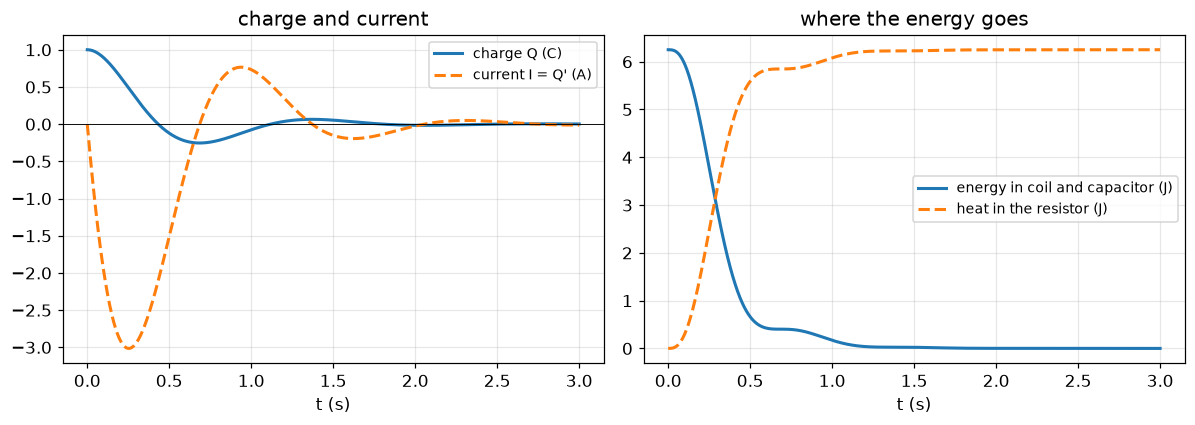

energy at the start: 6.25 J; strongest current -3.01 A at t = 0.25 s


In [7]:
INDUCTANCE, RESISTANCE, CAPACITANCE = 0.5, 2.0, 0.08       # henry, ohm, farad
CHARGE_START, CURRENT_START = 1.0, 0.0
CIRCUIT_TIME = 3.0

times = np.linspace(0.0, CIRCUIT_TIME, N_FINE)
charge = ol.free_response(times, INDUCTANCE, RESISTANCE, 1 / CAPACITANCE, CHARGE_START, CURRENT_START)
current = velocity(times, INDUCTANCE, RESISTANCE, 1 / CAPACITANCE, CHARGE_START, CURRENT_START)
stored = 0.5 * INDUCTANCE * current ** 2 + charge ** 2 / (2 * CAPACITANCE)
joule = cumulative_trapezoid(RESISTANCE * current ** 2, times, initial=0.0)

fig, (left, right) = plt.subplots(1, 2, figsize=FIGURE_SIZE)
left.plot(times, charge, "-", linewidth=2, label="charge Q (C)")
left.plot(times, current, "--", linewidth=2, label="current I = Q' (A)")
left.axhline(0.0, color="black", linewidth=0.6)
left.set_xlabel("t (s)")
left.set_title("charge and current")
left.legend(loc="upper right")
right.plot(times, stored, "-", linewidth=2, label="energy in coil and capacitor (J)")
right.plot(times, joule, "--", linewidth=2, label="heat in the resistor (J)")
right.set_xlabel("t (s)")
right.set_title("where the energy goes")
right.legend(loc="center right")
plt.tight_layout()
plt.show()

strongest = np.argmax(np.abs(current))
print(f"energy at the start: {stored[0]:g} J; strongest current {current[strongest]:.2f} A at t = {times[strongest]:.2f} s")
slopes = np.gradient(charge, times)                                        # numerical derivative: poor at the two ends
assert np.allclose(current[1:-1], slopes[1:-1], atol=1e-3)                 # the current is the derivative of the charge
assert np.max(np.abs(stored + joule - stored[0])) < BALANCE_TOLERANCE                   # energy balance

*The plot shows* the circuit over 3 seconds. Left: the charge (solid) falls from 1 C and
oscillates with decreasing swings; the current (dashed) starts at 0, is strongest (about
$-3.0$ A) at $t = 0.25$ s, when the capacitor is emptying fastest, and is zero exactly where the
charge has a maximum or a minimum. Right: the stored energy (solid) falls from 6.25 J in steps,
and the heat in the resistor (dashed) rises to 6.25 J: after one second almost all the energy
has become heat.

## 5. A map of all the equations $y'' + b\,y' + c\,y = 0$

Divide by the first coefficient: every equation of notebook 06 is one point $(b, c)$ of a plane.
For the spring, $b = c_{damper}/m \ge 0$ and $c = k/m > 0$: the springs fill the upper right
quarter. The roots are $r = \tfrac12\big(-b \pm \sqrt{b^2 - 4c}\big)$, so the **parabola**
$c = b^2/4$ divides the plane:

* above the parabola: complex roots, the solutions oscillate;
* on it: a repeated root (for the spring: critical damping);
* below it: two real roots; below the axis $c = 0$ they have opposite signs.

And all solutions tend to zero exactly when $b > 0$ **and** $c > 0$ (sum of the roots $-b$,
product $c$).

Predict: where on the map is $y'' + 4y = 0$? And $y'' - 2y' - 3y = 0$? What do their solutions do?

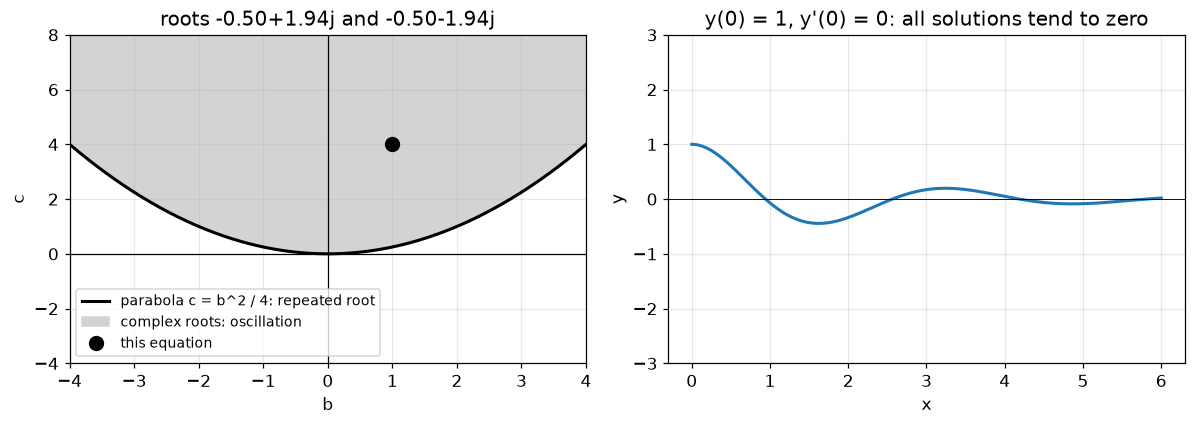

In [8]:
MAP_DEFAULTS = {"b": 1.0, "c": 4.0}
B_RANGE = (-4.0, 4.0, 0.25)                 # minimum, maximum, step
C_RANGE_MAP = (-4.0, 8.0, 0.25)
MAP_TIME = 6.0
WINDOW = 3.0                                # the solution is drawn between -WINDOW and WINDOW


def plot_map(b=MAP_DEFAULTS["b"], c=MAP_DEFAULTS["c"]):
    # left: the point (b, c) on the map; right: the solution with y(0) = 1, y'(0) = 0
    first, second = ol.characteristic_roots(1.0, b, c)
    values = np.linspace(B_RANGE[0], B_RANGE[1], N_POINTS)

    fig, (left, right) = plt.subplots(1, 2, figsize=FIGURE_SIZE)
    left.plot(values, values ** 2 / 4, "-", color="black", linewidth=2, label="parabola c = b^2 / 4: repeated root")
    left.fill_between(values, values ** 2 / 4, C_RANGE_MAP[1], color="lightgray",
                      label="complex roots: oscillation")
    left.axhline(0.0, color="black", linewidth=0.8)
    left.axvline(0.0, color="black", linewidth=0.8)
    left.plot(b, c, "o", color="black", markersize=9, label="this equation")
    left.set_xlim(B_RANGE[0], B_RANGE[1])
    left.set_ylim(C_RANGE_MAP[0], C_RANGE_MAP[1])
    left.set_xlabel("b")
    left.set_ylabel("c")
    left.set_title(f"roots {first:.2f} and {second:.2f}")
    left.legend(loc="lower left")

    times = np.linspace(0.0, MAP_TIME, N_POINTS)
    solution = ol.constant_coefficient_solution(times, 1.0, b, c, 1.0, 0.0)
    right.plot(times, np.clip(solution, -2 * WINDOW, 2 * WINDOW), "-", linewidth=2)
    right.axhline(0.0, color="black", linewidth=0.6)
    right.set_ylim(-WINDOW, WINDOW)
    right.set_xlabel("x")
    right.set_ylabel("y")
    fate = "all solutions tend to zero" if b > 0 and c > 0 else "not all solutions tend to zero"
    right.set_title(f"y(0) = 1, y'(0) = 0: {fate}")
    plt.tight_layout()
    plt.show()


plot_map()

In [9]:
interact(plot_map,
         b=FloatSlider(value=MAP_DEFAULTS["b"], min=B_RANGE[0], max=B_RANGE[1], step=B_RANGE[2], description="b",
                       continuous_update=False),
         c=FloatSlider(value=MAP_DEFAULTS["c"], min=C_RANGE_MAP[0], max=C_RANGE_MAP[1], step=C_RANGE_MAP[2], description="c",
                       continuous_update=False));

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='b', max=4.0, min=-4.0, step...

*The static plot shows*, for $b = 1$, $c = 4$. Left: the map. The parabola $c = b^2/4$ opens
upwards from the origin; the gray region above it is where the roots are complex; the black
dot $(1, 4)$ is inside it, in the upper right quarter. Right: the solution with $y(0) = 1$,
$y'(0) = 0$: an oscillation that dies out, with roots $-0.5 \pm 1.94\,i$.

($y'' + 4y = 0$ is the point $(0, 4)$, on the vertical axis above the parabola: oscillation that
neither grows nor dies. $y'' - 2y' - 3y = 0$ is $(-2, -3)$, below the horizontal axis: roots 3
and $-1$, and the solution grows without bound.)

Move the point across the parabola in the upper right quarter: this is the spring passing
through critical damping. Move it across the vertical axis above the parabola: the oscillation
changes from dying out to growing ("negative damping").

## 6. Summary

| Statement | Formula |
|---|---|
| Damping ratio | $\zeta = c/c_{crit} = p/\omega_0$ |
| Roots while underdamped | on the circle $\lvert r\rvert = \omega_0$ |
| Decay rate | $\zeta\omega_0$ for $\zeta \le 1$; $\omega_0(\zeta - \sqrt{\zeta^2 - 1})$ for $\zeta \ge 1$; largest at $\zeta = 1$ |
| Energy | $E = \tfrac12mx'^2 + \tfrac12kx^2$, $\;E' = -c\,x'^2$ |
| Areas in the plane of states | multiplied by $e^{-(c/m)t}$, whatever $k$ is |
| Circuit | the same with $L$, $R$, $1/C$; heat $R\,I^2$ |
| Map | oscillation above $c = b^2/4$; decay for $b > 0$ and $c > 0$ |

## 7. Problems

Ordinary problems, without automatic checks.

1. *(Adkins and Davidson, Section 3.6, Example 3)* Solve $\tfrac18x'' + 4x' + 16x = 0$,
   $x(0) = 1$, $x'(0) = 0$. Does the body ever pass through the rest position?
2. In an underdamped motion, the logarithm of the ratio of two successive maxima is called the
   *logarithmic decrement* $\delta$. Show that $\delta = 2\pi p/\omega_1$ and express $\zeta$ with
   $\delta$. (This is how $\zeta$ is measured.)
3. Prove the formula for the decay rate of Section 1, and that it is largest at $\zeta = 1$.
4. With Section 3, explain why no damper $c > 0$ can keep the area of the cloud, and why no
   spring $k$ can change the law of the area.
5. For which resistance is the circuit of Section 4 critically damped? Write the charge $Q(t)$
   for that resistance.
6. For the motion of Lebl's Example 2.4.1 ($m = 2$, $k = 8$, $x(0) = 0.5$, $x'(0) = 1$, no
   damper) compute the energy, and check that it equals $\tfrac12\,k\,A^2$ with the amplitude $A$
   of notebook 07. Show that this is true for every undamped motion.

<details>
<summary>Final answers (after trying)</summary>

1. Roots $-16 \pm 8\sqrt2$, about $-4.686$ and $-27.314$;
   $x \approx 1.207\,e^{-4.686t} - 0.207\,e^{-27.314t}$, positive for all $t \ge 0$: never.
2. One period $2\pi/\omega_1$ multiplies the envelope by $e^{-2\pi p/\omega_1}$. With
   $p = \zeta\omega_0$ and $\omega_1 = \omega_0\sqrt{1 - \zeta^2}$:
   $\;\zeta = \dfrac{\delta}{\sqrt{4\pi^2 + \delta^2}}$.
3. For $\zeta \ge 1$, $\zeta - \sqrt{\zeta^2 - 1} = \dfrac{1}{\zeta + \sqrt{\zeta^2 - 1}}$, which
   decreases; for $\zeta \le 1$ the rate $\zeta\omega_0$ increases.
4. The factor is $e^{-(c/m)t} < 1$ for every $c > 0$ and $t > 0$, and $k$ is not in it.
5. $R = 2\sqrt{L/C} = 5$ ohm; $Q = (1 + 5t)\,e^{-5t}$.
6. $E = \tfrac12\cdot 2\cdot 1^2 + \tfrac12\cdot 8\cdot 0.5^2 = 2$ J, and
   $\tfrac12\cdot 8\cdot 0.5 = 2$ J. In general, at a maximum of $x$ the velocity is zero and
   $x = A$.

</details>

**Where to go next:** forced vibrations and resonance (Session 15).